In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import  accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
df=pd.read_csv(r"E:\Diabetes Prediction Web Browser\diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
features=['Glucose','BloodPressure','Insulin','BMI','DiabetesPedigreeFunction','Age','SkinThickness']
x=df[features]
y=df['Outcome'] 

In [4]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [5]:
model=LogisticRegression()
model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [6]:
y_pred = model.predict(x_test)

In [7]:
accuracy_score=accuracy_score(y_test,y_pred)
confusion_matrix=confusion_matrix(y_test,y_pred)
classification_report=classification_report(y_test,y_pred)
print("accuracy_score:\n",accuracy_score)
print("confusion_matrix:\n",confusion_matrix)
print("classification_report:\n",classification_report)

accuracy_score:
 0.7662337662337663
confusion_matrix:
 [[82 17]
 [19 36]]
classification_report:
               precision    recall  f1-score   support

           0       0.81      0.83      0.82        99
           1       0.68      0.65      0.67        55

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.76      0.77      0.77       154



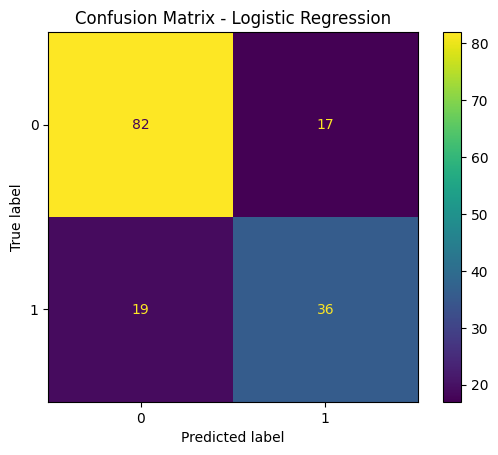

In [8]:

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [9]:
def predict_outcome(glucose, bloodpressure, insulin, bmi, DiabetesPedigreeFunction,age,SkinThickness):
  """Predicts the outcome (diabetes or not) based on the input features."""
  predicted_outcome = model.predict(np.array([[glucose, bloodpressure, insulin, bmi, DiabetesPedigreeFunction,age,SkinThickness]]))
  return predicted_outcome[0]

# Example usage (replace with actual input values)
glucose = float(input("Enter Glucose: "))
bloodpressure = float(input("Enter BloodPressure: "))
insulin = float(input("Enter Insulin: "))
bmi = float(input("Enter BMI: "))
DiabetesPedigreeFunction = float(input("Enter DiabetesPedigreeFunction: "))
age = float(input("Enter Age: "))
SkinThickness = float(input("Enter SkinThickness: "))

predicted_outcome = predict_outcome(glucose, bloodpressure, insulin, bmi,DiabetesPedigreeFunction,age,SkinThickness)
print("Predicted Outcome (0: No Diabetes, 1: Diabetes):", predicted_outcome)

Enter Glucose:  148
Enter BloodPressure:  72
Enter Insulin:  0
Enter BMI:  33.6
Enter DiabetesPedigreeFunction:  0.627
Enter Age:  50
Enter SkinThickness:  35


Predicted Outcome (0: No Diabetes, 1: Diabetes): 1


C:\Users\Abdus Soyim\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [10]:
import pickle
pickle.dump(model,open(r'E:\Diabetes Prediction Web Brower\diabetes.csv.pkl','wb'))